# POD en couleur des images de la Romanche

Décomposition orthogonale aux valeurs propres (POD) de la bande utile (y 500-1200), en couleur : chaque image est un vecteur où l'on met bout à bout les canaux R, G, B de tous les pixels, et l'on calcule **une seule** POD sur ces vecteurs (les modes sont des images couleur).

Méthode des *snapshots* : on diagonalise la matrice $A A^T$ ($n \times n$, $n$ = nombre d'images) au lieu de $A^T A$ (taille = nombre de pixels × 3).

Les images manquantes sont téléchargées dans `data/raw/` (ignoré par git).

In [1]:
import sys
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from bucket import Bucket, DATA_DIR

plt.rcParams["figure.dpi"] = 70
b = Bucket()

CROP_Y0, CROP_Y1 = 500, 1200   # bande utile : sous le haut de l'enrochement, au-dessus de la plage du premier plan
W0 = 1919                      # largeur des images


def fetch(key):
    """Chemin local de l'image, téléchargée dans data/raw/ si elle n'y est pas déjà."""
    p = DATA_DIR / key
    if not p.exists():
        p.parent.mkdir(parents=True, exist_ok=True)
        b.s3.download_file(b.name, key, str(p))
    return p


def load_band(key, scale=1, gray=False):
    """Bande CROP_Y0-CROP_Y1 en float (0-1), décodée directement à 1/scale (rapide)."""
    im = Image.open(fetch(key))
    if scale > 1:
        im.draft("L" if gray else "RGB", (im.size[0] // scale, im.size[1] // scale))
    s = W0 / im.size[0]
    im = im.convert("L" if gray else "RGB").crop((0, round(CROP_Y0 / s), im.size[0], round(CROP_Y1 / s)))
    return np.asarray(im, dtype=np.float32) / 255


## Paramètres et sélection des images
On prend `N_IMAGES` images de jour (8h-17h) réparties uniformément dans le temps, réduites à 1/`SCALE` pour que le calcul reste rapide. Les images trop sombres sont écartées.

In [2]:
N_IMAGES = 1000   # nombre d'images utilisées pour la POD (toutes : ~4300, ~2,7 Go à télécharger)
SCALE = 8         # réduction (8 -> bande de 87 x 240 pixels)
N_MODES = 200     # nombre de modes gardés

objs = [o for o in b.list_images()
        if "_permission" not in o["Key"] and 8 <= int(o["Key"].split("/")[-1][:2]) < 17]
objs.sort(key=lambda o: o["Key"])
sel = [objs[i] for i in np.round(np.linspace(0, len(objs) - 1, min(N_IMAGES, len(objs)))).astype(int)]
print(len(objs), "images de jour dans le bucket ;", len(sel), "sélectionnées")

with ThreadPoolExecutor(16) as ex:
    bands = list(ex.map(lambda o: load_band(o["Key"], SCALE), sel))
keep = [i for i, x in enumerate(bands) if x.mean() > 20 / 255]           # on retire les images noires
X = np.stack([bands[i] for i in keep])
keys = [sel[i]["Key"] for i in keep]
dates = [datetime.strptime("".join(k.split("/")[1:4]) + k.split("/")[4][:6], "%Y%m%d%H%M%S") for k in keys]
n, h, w, c = X.shape
print(n, "images gardées, bande", h, "x", w, "x", c, "=", h * w * c, "valeurs par image")

3113 images de jour dans le bucket ; 1000 sélectionnées


1000 images gardées, bande 87 x 240 x 3 = 62640 valeurs par image


## Calcul de la POD

In [3]:
def pod(A, nm):
    """Modes POD (lignes orthonormées) et valeurs propres d'une matrice centrée A (n, p)."""
    lam, V = np.linalg.eigh((A @ A.T).astype(np.float64))
    lam, V = lam[::-1], V[:, ::-1]
    nm = min(nm, len(lam))
    modes = ((A.T @ V[:, :nm].astype(np.float32)) / np.sqrt(lam[:nm]).astype(np.float32)).T
    return modes, lam


F = X.reshape(n, -1)
xbar = F.mean(axis=0)
A = F - xbar
modes, lam = pod(A, N_MODES)
coefs = A @ modes.T                 # coefficients a_k de chaque image
energy = lam / lam.sum()
print("énergie des 6 premiers modes (%) :", np.round(100 * energy[:6], 1))

énergie des 6 premiers modes (%) : [44.9 22.1  5.8  3.5  2.6  2.1]


## Image moyenne et spectre POD

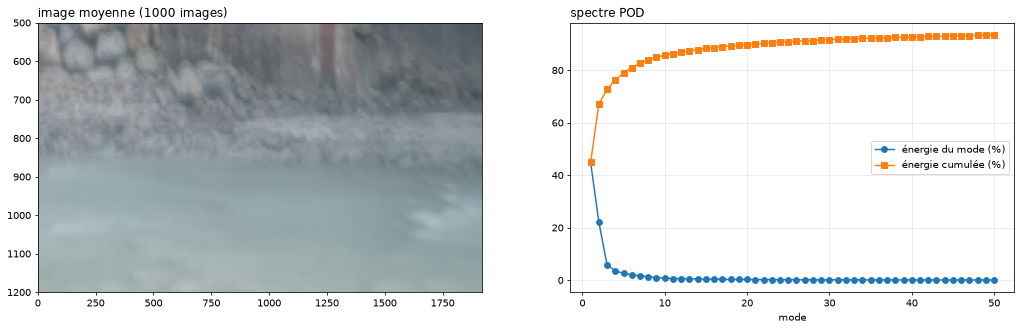

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
ax[0].imshow(np.clip(xbar.reshape(h, w, c), 0, 1), extent=[0, W0, CROP_Y1, CROP_Y0], aspect="auto")
ax[0].set_title(f"image moyenne ({n} images)", loc="left")
K = np.arange(1, 51)
ax[1].plot(K, 100 * energy[:50], "o-", label="énergie du mode (%)")
ax[1].plot(K, 100 * np.cumsum(energy[:50]), "s-", label="énergie cumulée (%)")
ax[1].set_xlabel("mode"); ax[1].grid(alpha=.3); ax[1].legend(); ax[1].set_title("spectre POD", loc="left")
plt.show()

## Les premiers modes et leurs coefficients dans le temps
Affichage d'un mode : gris = 0 ; la teinte indique dans quel sens le mode décale la couleur de chaque pixel (pour un coefficient positif ; la teinte complémentaire pour un coefficient négatif).

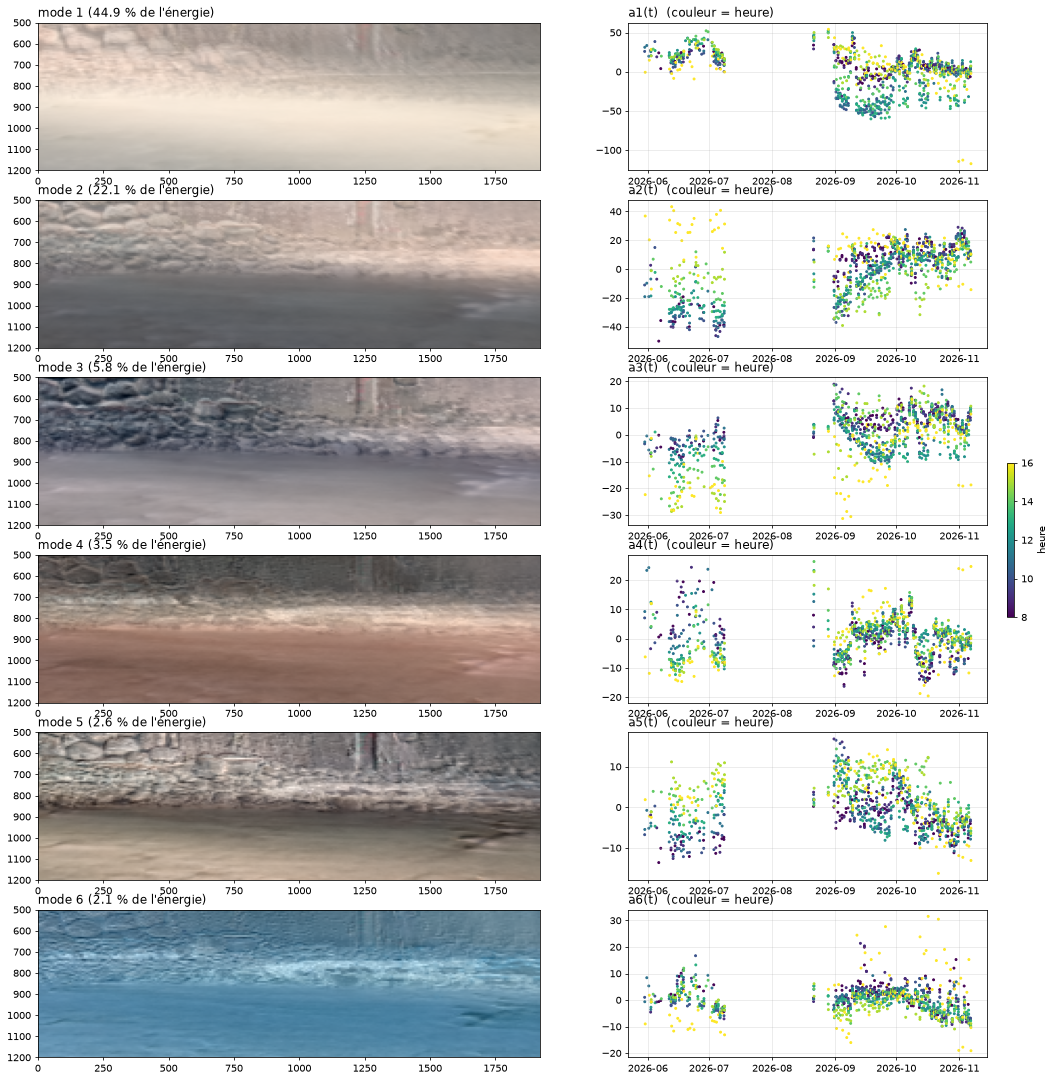

In [5]:
N_SHOW = 6
fig, ax = plt.subplots(N_SHOW, 2, figsize=(18, 3.2 * N_SHOW), gridspec_kw={"width_ratios": [1.3, 1]})
hours = [d.hour for d in dates]
for k in range(N_SHOW):
    m = modes[k].reshape(h, w, c)
    ax[k, 0].imshow(np.clip(0.5 + m / (2 * np.abs(m).max()), 0, 1), extent=[0, W0, CROP_Y1, CROP_Y0], aspect="auto")
    ax[k, 0].set_title(f"mode {k + 1} ({100 * energy[k]:.1f} % de l'énergie)", loc="left")
    sc = ax[k, 1].scatter(dates, coefs[:, k], s=4, c=hours, cmap="viridis")
    ax[k, 1].set_title(f"a{k + 1}(t)  (couleur = heure)", loc="left"); ax[k, 1].grid(alpha=.3)
plt.colorbar(sc, ax=ax[:, 1], fraction=0.02, label="heure")
plt.show()

## Reconstruction de quelques images avec K modes
$x \approx \bar{x} + \sum_{k=1}^{K} a_k \varphi_k$ ; le **résidu** est ce qui reste : original − reconstruction.

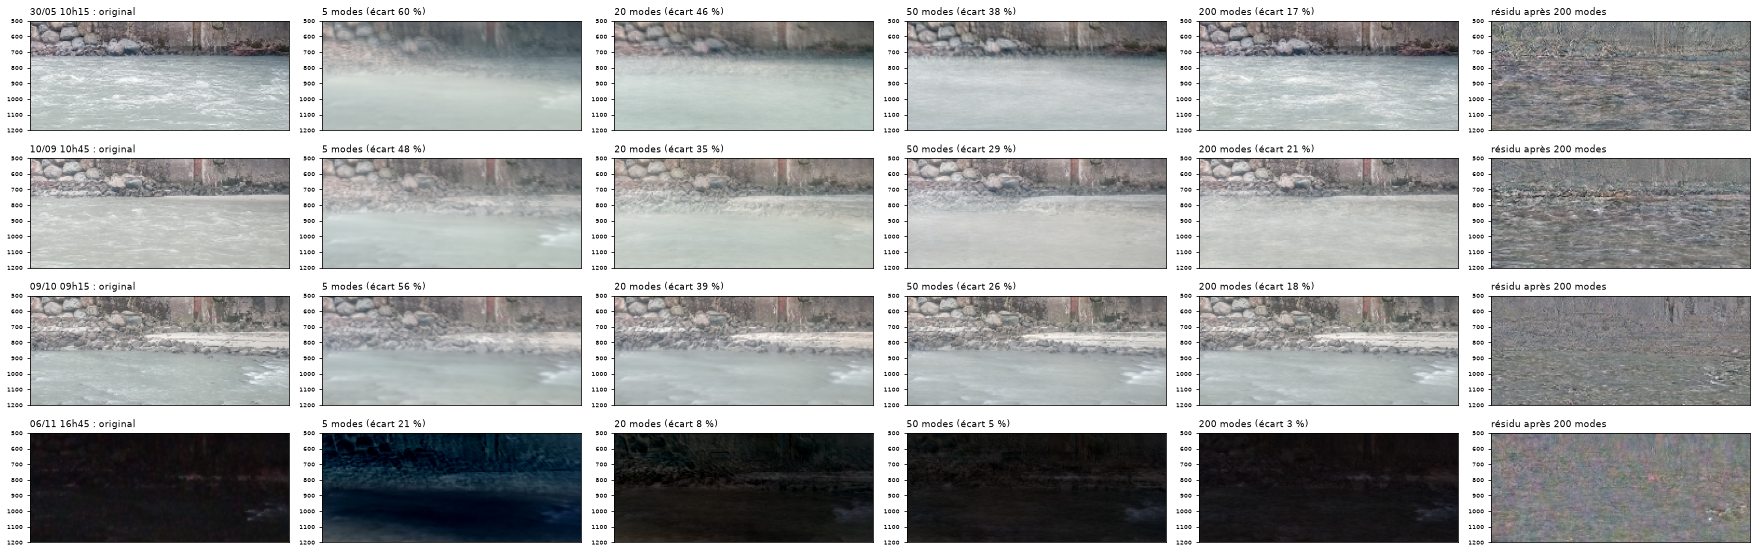

In [6]:
KS = [5, 20, 50, 200]
idx = np.round(np.linspace(0, n - 1, 4)).astype(int)
fig, ax = plt.subplots(len(idx), len(KS) + 2, figsize=(4.2 * (len(KS) + 2), 2.0 * len(idx)))
for i, j in enumerate(idx):
    d = A[j]
    ax[i, 0].imshow(np.clip(X[j], 0, 1), extent=[0, W0, CROP_Y1, CROP_Y0], aspect="auto")
    ax[i, 0].set_title(dates[j].strftime("%d/%m %Hh%M") + " : original", fontsize=9, loc="left")
    for jj, K in enumerate(KS, 1):
        rec = xbar + coefs[j, :K] @ modes[:K]
        err = np.linalg.norm(d - coefs[j, :K] @ modes[:K]) / np.linalg.norm(d)
        ax[i, jj].imshow(np.clip(rec.reshape(h, w, c), 0, 1), extent=[0, W0, CROP_Y1, CROP_Y0], aspect="auto")
        ax[i, jj].set_title(f"{K} modes (écart {100 * err:.0f} %)", fontsize=9, loc="left")
    res = (d - coefs[j, :KS[-1]] @ modes[:KS[-1]]).reshape(h, w, c)
    ax[i, -1].imshow(np.clip(0.5 + res / (2 * np.abs(res).max()), 0, 1), extent=[0, W0, CROP_Y1, CROP_Y0], aspect="auto")
    ax[i, -1].set_title(f"résidu après {KS[-1]} modes", fontsize=9, loc="left")
for a in ax.ravel():
    a.set_xticks([]); a.tick_params(labelsize=6)
plt.tight_layout(); plt.show()

## Erreur en fonction du nombre de modes
Erreur relative $\|\text{résidu}\| / \|x - \bar{x}\|$, moyennée sur `N_TEST` images.
- **dans la base** : ces images ont servi à calculer la POD ;
- **hors base** : POD recalculée sans elles (vraie capacité à représenter une image nouvelle).

Les modes étant orthonormés, $\|\text{résidu}\|^2 = \|x-\bar{x}\|^2 - \sum_{k\le K} a_k^2$ : le calcul pour tous les K est quasi gratuit.

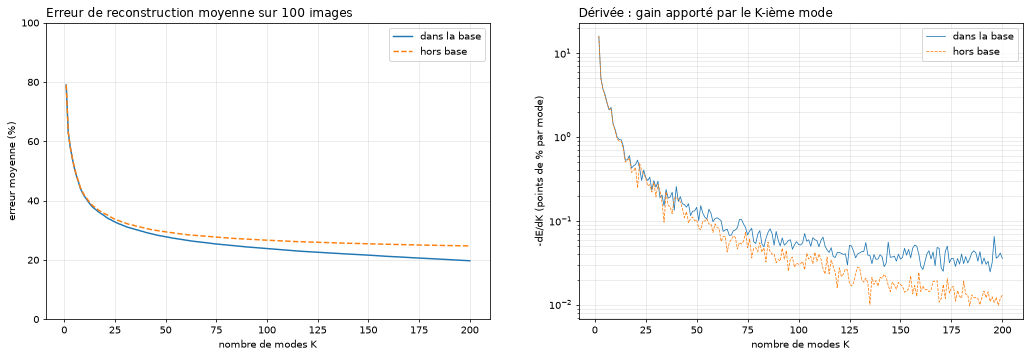

K=  1  dans la base  79.0 %   hors base  79.0 %
K= 10  dans la base  41.5 %   hors base  41.8 %
K= 20  dans la base  34.8 %   hors base  35.6 %
K= 50  dans la base  27.8 %   hors base  29.5 %
K=100  dans la base  23.9 %   hors base  26.7 %
K=200  dans la base  19.7 %   hors base  24.7 %


In [7]:
N_TEST = 100
test = np.round(np.linspace(0, n - 1, N_TEST)).astype(int)
train = np.setdiff1d(np.arange(n), test)


def mean_error(modes_, mean_, Xtest):
    D = Xtest - mean_
    a = D @ modes_.T
    d2 = (D.astype(np.float64) ** 2).sum(axis=1)
    cum = np.cumsum(a.astype(np.float64) ** 2, axis=1)
    return np.mean(np.sqrt(np.clip(d2[:, None] - cum, 0, None) / d2[:, None]), axis=0)


e_in = mean_error(modes, xbar, F[test])
m_tr = F[train].mean(axis=0)
modes_tr, _ = pod(F[train] - m_tr, N_MODES)
e_out = mean_error(modes_tr, m_tr, F[test])

K = np.arange(1, len(e_in) + 1)
fig, ax = plt.subplots(1, 2, figsize=(18, 5.5))
ax[0].plot(K, 100 * e_in, label="dans la base"); ax[0].plot(K, 100 * e_out, "--", label="hors base")
ax[0].set_ylim(0, 100); ax[0].set_xlabel("nombre de modes K"); ax[0].set_ylabel("erreur moyenne (%)")
ax[0].set_title(f"Erreur de reconstruction moyenne sur {N_TEST} images", loc="left")
ax[1].plot(K[1:], -100 * np.diff(e_in), lw=.8, label="dans la base")
ax[1].plot(K[1:], -100 * np.diff(e_out), "--", lw=.8, label="hors base")
ax[1].set_yscale("log"); ax[1].set_xlabel("nombre de modes K")
ax[1].set_ylabel("-dE/dK (points de % par mode)"); ax[1].set_title("Dérivée : gain apporté par le K-ième mode", loc="left")
for a in ax:
    a.grid(alpha=.3, which="both"); a.legend()
plt.show()
for k in (1, 10, 20, 50, 100, 200):
    if k <= len(e_in):
        print(f"K={k:3d}  dans la base {100 * e_in[k - 1]:5.1f} %   hors base {100 * e_out[k - 1]:5.1f} %")